# 01 · Exploración de datos
Análisis descriptivo de las variables académicas y de encuestas.

> **Advertencia:** mientras no se disponga de datos institucionales, estos notebooks usan el dataset **SINTÉTICO** `data/sample/synthetic_training_dataset.csv`. Los resultados sirven sólo para verificar técnicamente el pipeline y **no deben reportarse como hallazgos académicos**.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent.parent / "backend"))  # sipd_ml vive en backend/
import pandas as pd
from sipd_ml import config
pd.set_option("display.max_columns", 30)

In [2]:
from sipd_ml.synthetic import generate_training_dataset
if not config.SYNTHETIC_DATASET_PATH.exists():
    config.SAMPLE_DATA_DIR.mkdir(parents=True, exist_ok=True)
    generate_training_dataset().to_csv(config.SYNTHETIC_DATASET_PATH, index=False)
df = pd.read_csv(config.SYNTHETIC_DATASET_PATH)
print(df.shape)
df.head()

(4000, 16)


,is_synthetic,program_code,semester,gpa,previous_gpa,credits_enrolled,credits_approved,credits_failed,failed_subjects,attendance_percentage,course_repetitions,works_while_studying,socioeconomic_stratum,financial_difficulty,motivation_level,dropout
0,True,SIS,4,2.80,2.82,17,17,0,0,74.2,0,0.0,2.0,5.0,1.0,1
1,True,IND,9,2.29,2.32,12,12,0,0,79.3,2,1.0,5.0,1.0,NaN,0
2,True,IND,1,4.35,NaN,14,14,0,0,90.9,0,NaN,NaN,3.0,NaN,0
3,True,CIV,5,4.71,4.68,17,17,0,0,100.0,0,1.0,NaN,3.0,NaN,0
4,True,CIV,9,3.28,3.85,19,19,0,0,79.9,1,1.0,1.0,4.0,NaN,0


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
semester,4000.0,5.391000,2.868044,1.00,3.0000,5.00,8.0000,10.0
gpa,4000.0,3.545545,0.537891,1.39,3.1900,3.54,3.8900,5.0
previous_gpa,3574.0,3.493811,0.619635,1.41,3.0725,3.49,3.9275,5.0
credits_enrolled,4000.0,15.014000,3.181090,10.00,12.0000,15.00,18.0000,20.0
credits_approved,4000.0,14.994500,3.198910,4.00,12.0000,15.00,18.0000,20.0
credits_failed,4000.0,0.019500,0.274114,0.00,0.0000,0.00,0.0000,8.0
failed_subjects,4000.0,0.006750,0.093309,0.00,0.0000,0.00,0.0000,3.0
attendance_percentage,4000.0,84.011600,8.903132,50.20,78.2000,84.10,90.5000,100.0
course_repetitions,4000.0,0.787500,0.971123,0.00,0.0000,1.00,1.0000,5.0
works_while_studying,3182.0,0.359208,0.479844,0.00,0.0000,0.00,1.0000,1.0


## Valores faltantes
Las variables de encuesta son opcionales; el pipeline las imputa.

In [4]:
(df.isna().mean() * 100).round(1).sort_values(ascending=False).to_frame('% faltante')

,% faltante
motivation_level,25.5
financial_difficulty,24.5
works_while_studying,20.4
socioeconomic_stratum,20.0
previous_gpa,10.6
is_synthetic,0.0
semester,0.0
program_code,0.0
credits_failed,0.0
credits_approved,0.0


## Balance de la variable objetivo

In [5]:
df['dropout'].value_counts(normalize=True).rename({0: 'Permanece', 1: 'Deserta'}).round(3)

dropout
Permanece    0.788
Deserta      0.212
Name: proportion, dtype: float64

## Relación descriptiva de variables con la etiqueta
(Asociaciones, no relaciones causales.)

In [6]:
df.groupby('dropout')[['gpa', 'attendance_percentage', 'failed_subjects', 'course_repetitions']].mean().round(2)

,gpa,attendance_percentage,failed_subjects,course_repetitions
dropout,,,,
0,3.66,85.83,0.00,0.66
1,3.11,77.23,0.02,1.27


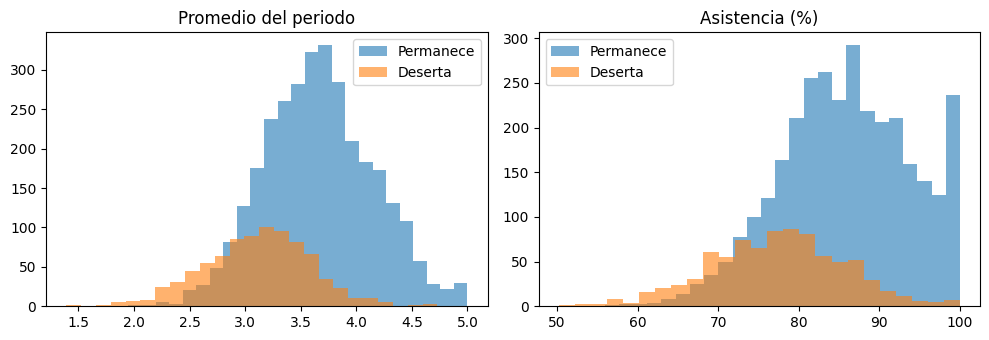

In [7]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ['gpa', 'attendance_percentage']):
    for label, group in df.groupby('dropout'):
        ax.hist(group[col], bins=25, alpha=0.6, label='Deserta' if label else 'Permanece')
    ax.set_title(config.FEATURE_LABELS[col]); ax.legend()
plt.tight_layout()